In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y número de operarios necesarios por actividad se adjunta. Todas las actividades se han programado en su inicio más temprano.

In [3]:
pregunta_1 = "1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  "
pregunta_2 = "2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  "
pregunta_3 = "3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  "
pregunta_4 = "4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  

2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  

3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  

4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 7       , 3        ),
    ('B'     , '---'      , 1       , 1        ),
    ('C'     , '---'      , 8       , 2        ),
    ('D'     , 'B,C'      , 2       , 3        ),
    ('E'     , 'B,C'      , 7       , 4        ),
    ('F'     , 'E'        , 2       , 1        ),
    ('G'     , 'A,D,E'    , 2       , 1        ),
    ('H'     , 'D'        , 2       , 3        ),
    ('I'     , 'F,G,H'    , 3       , 4        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,7,3
B,---,1,1
C,---,8,2
D,"B,C",2,3
E,"B,C",7,4
F,E,2,1
G,"A,D,E",2,1
H,D,2,3
I,"F,G,H",3,4


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
    'I': 'Grabación de sonido directo',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató
I,Grabación de sonido directo


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el diagrama de Gantt y el diagrama de cargas. ¿Cuál es el número máximo de operarios necesario y en qué semanas?  

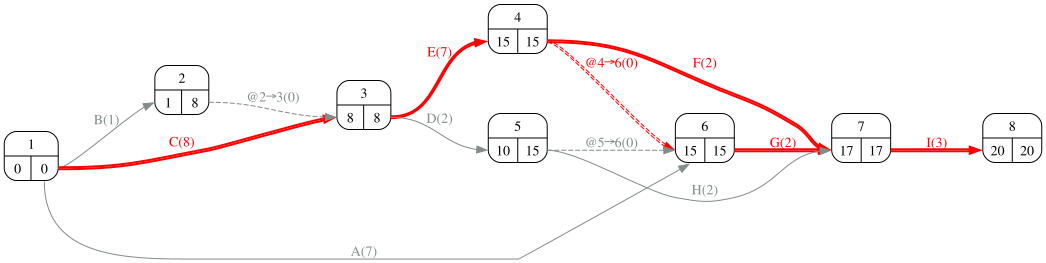

In [8]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

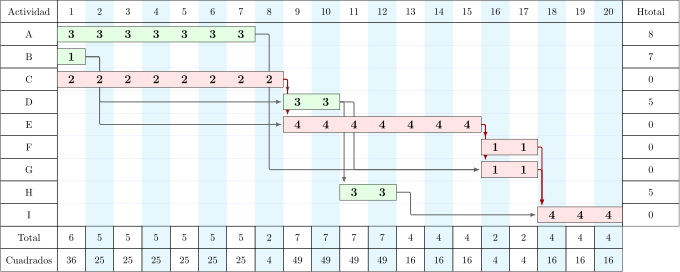

In [9]:
#| fig-cap: "Diagrama de Gantt con las cargas de operarios (inicios más tempranos)"
#| label: fig-ganttInicial
proyecto_inicial = proyecto.copy()
gantt_inicial, dibujo = proyecto_inicial.gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

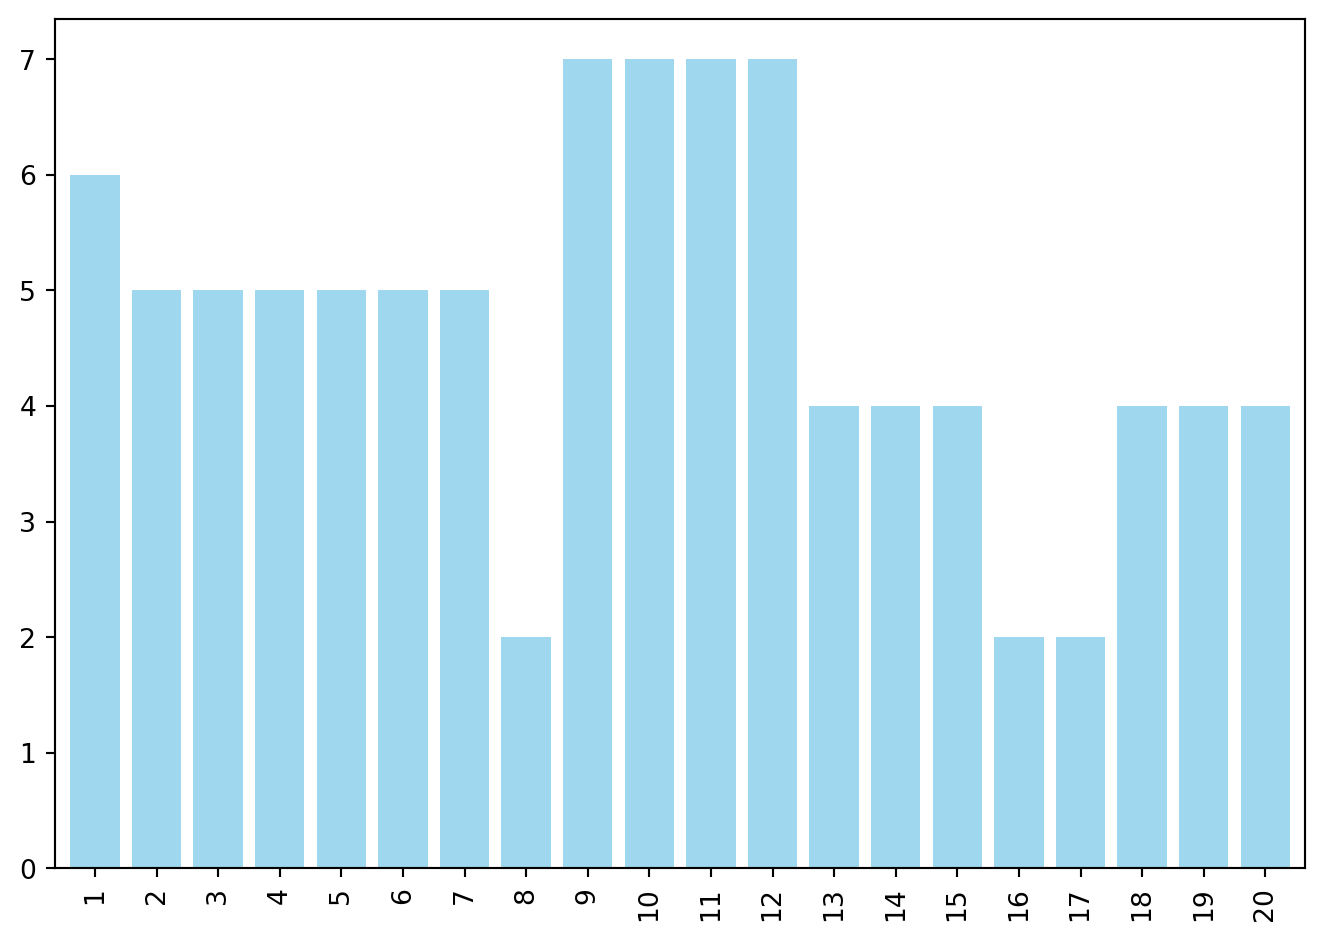

In [10]:
#| fig-cap: "Diagrama de cargas de operarios"
#| label: fig-cargasInicial
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=None)

In [11]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
semanas_pico = cargas.index[cargas == cargas.max()].tolist()
Markdown(f'El máximo de operarios es {int(cargas.max())}, en las semanas {", ".join(map(str, semanas_pico))}. '
         f'La media es {cargas.mean():.2f} operarios/semana.')

El máximo de operarios es 7, en las semanas 9, 10, 11, 12. La media es 4.70 operarios/semana.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. ¿Está nivelado el consumo de recursos? Calcule la suma de cuadrados de las cargas como medida de desnivel.  

La suma de cuadrados de las cargas, $\sum_t c_t^2$, penaliza los picos: para una misma carga total es mínima cuando el perfil es plano. Es la función objetivo de la nivelación.

In [13]:
suma_cuadrados_inicial = float((cargas ** 2).sum())
Markdown(f'Suma de cuadrados inicial: {suma_cuadrados_inicial:.0f}. La carga total es {cargas.sum():.0f} operarios·semana; '
         f'si se repartiera uniformemente en {len(cargas)} semanas la suma de cuadrados sería {len(cargas) * cargas.mean() ** 2:.0f}.')

Suma de cuadrados inicial: 490. La carga total es 94 operarios·semana; si se repartiera uniformemente en 20 semanas la suma de cuadrados sería 442.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Nivele los recursos desplazando actividades no críticas dentro de su holgura, sin alargar el proyecto, con el algoritmo de mínimos cuadrados. Indique qué actividades desplaza y cuánto.  

El algoritmo recorre las actividades no críticas (por orden de fin más temprano) y, para cada una, prueba todos los desplazamientos dentro de su holgura eligiendo el que minimiza la suma de cuadrados. La tabla muestra la suma de cuadrados para cada desplazamiento posible, con el mínimo resaltado.

In [15]:
#| tbl-cap: "Suma de cuadrados para cada desplazamiento posible"
#| label: tbl-cuadrados
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
cuadrados

,0,1,2,3,4,5,6,7,8
activity,,,,,,,,,
B,490,490,490,490,490,490,490,484,
A,484,490,520,550,580,610,622,634,640
D,484,484,484,484,472,460,,,
H,460,,,,,,,,


In [16]:
#| tbl-cap: "Desplazamientos elegidos"
#| label: tbl-desplazamientos
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
B,7
D,5


## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Compare el diagrama de cargas antes y después: máximo de operarios y suma de cuadrados.  

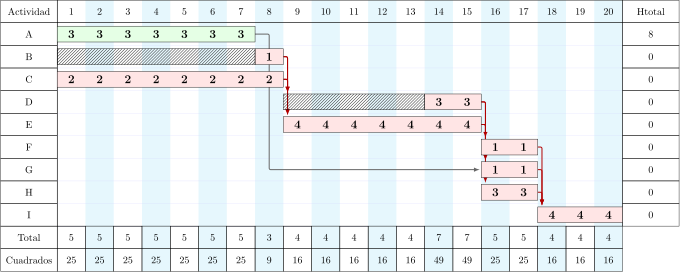

In [18]:
#| fig-cap: "Diagrama de Gantt tras la nivelación"
#| label: fig-ganttNivelado
gantt_nivelado, dibujo = proyecto_nivelado.gantt_cargas(datos_nivelados, 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

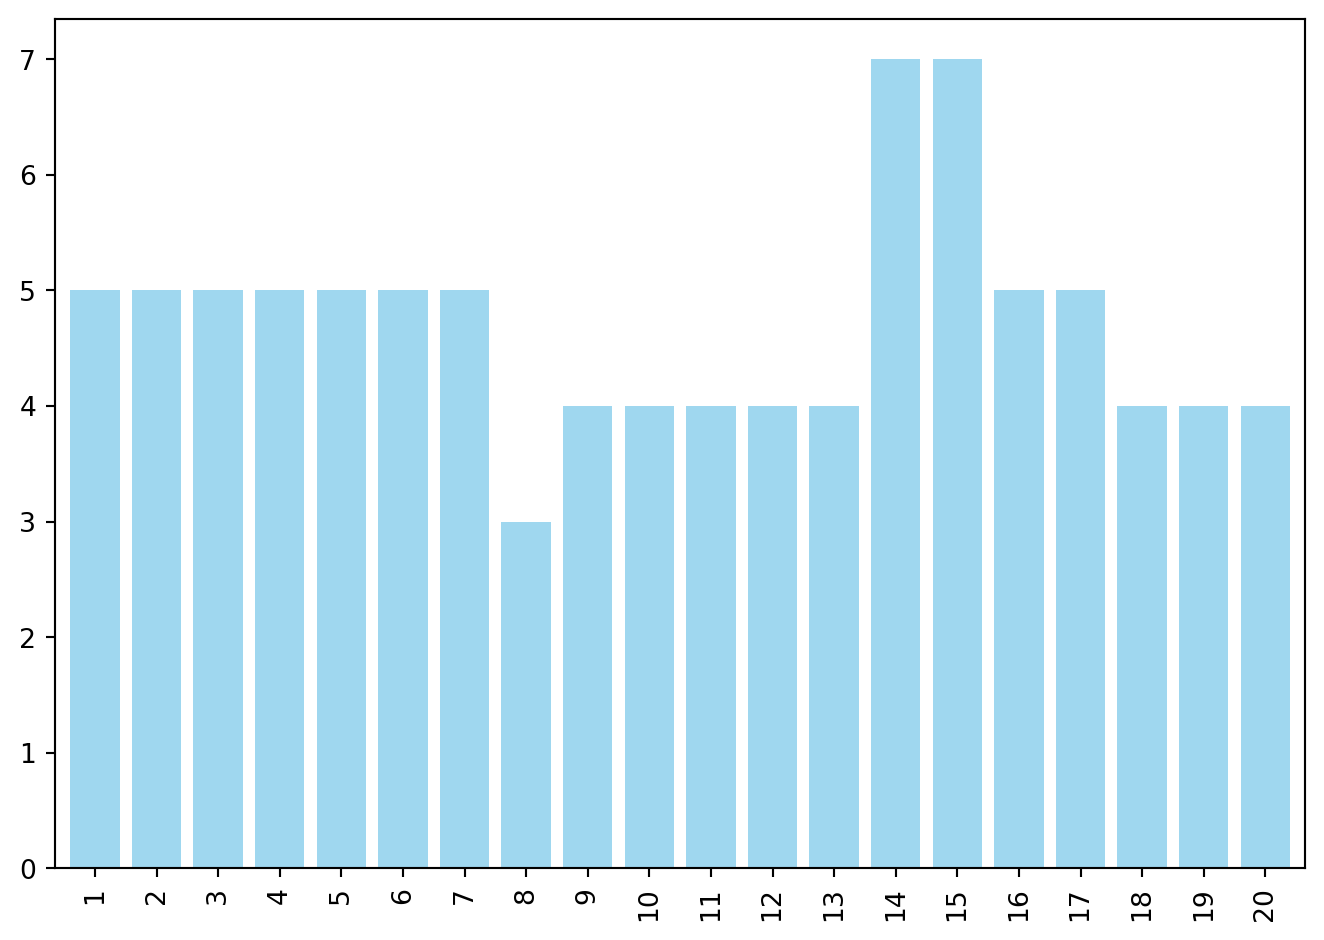

In [19]:
#| fig-cap: "Diagrama de cargas tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=None)

In [20]:
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
pd.DataFrame({'antes': [cargas.max(), (cargas ** 2).sum(), len(cargas)],
              'después': [cargas_niveladas.max(), (cargas_niveladas ** 2).sum(), len(cargas_niveladas)]},
             index=['máximo de operarios', 'suma de cuadrados', 'duración']).astype(int)

,antes,después
máximo de operarios,7,7
suma de cuadrados,490,460
duración,20,20


La duración no cambia porque sólo se han movido actividades dentro de su holgura; el perfil es más plano y el máximo de operarios, menor o igual.